--- Missing Values Check ---
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

--- Summary Statistics ---
                             Date  Estimated Unemployment Rate (%)  \
count                         740                       740.000000   
mean   2019-12-12 18:36:58.378378                        11.787946   
min           2019-05-31 00:00:00                         0.000000   
25%           2019-08-31 00:00:00                         4.657500   
50%           2019-11-30 00:00:00                         8.350000   
75%           2020-03-31 00:00:00                        15.887500   
max           2020-06-30 00:00:00                        76.740000   
std                           NaN               

C:\Users\A\AppData\Local\Temp\ipykernel_2232\1324687248.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Estimated Unemployment Rate (%)', y='Region', data=region_avg.head(10), palette='viridis')


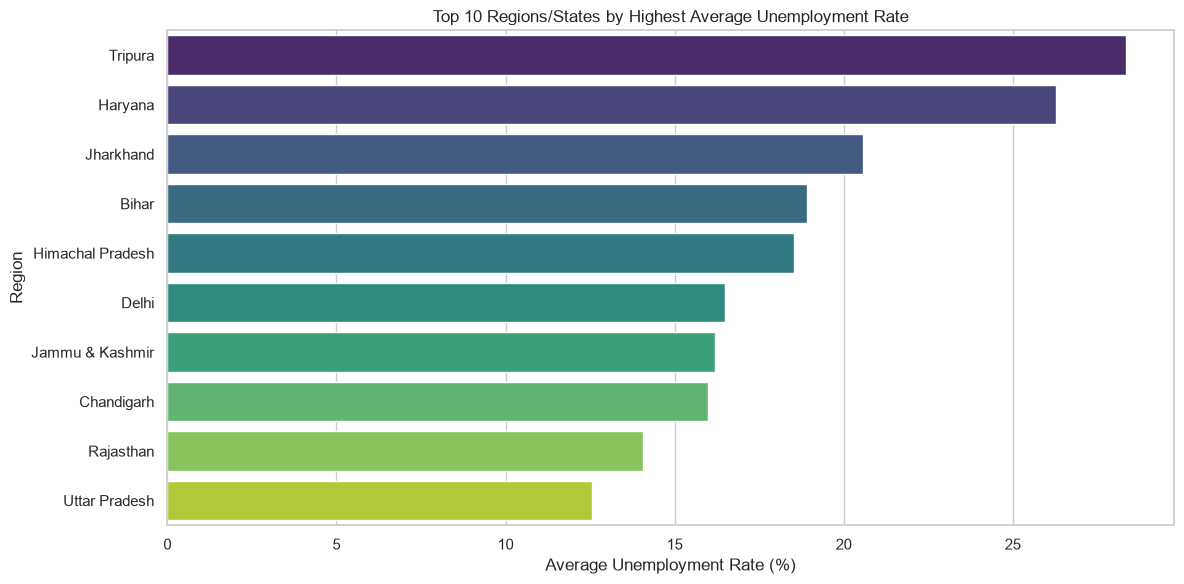

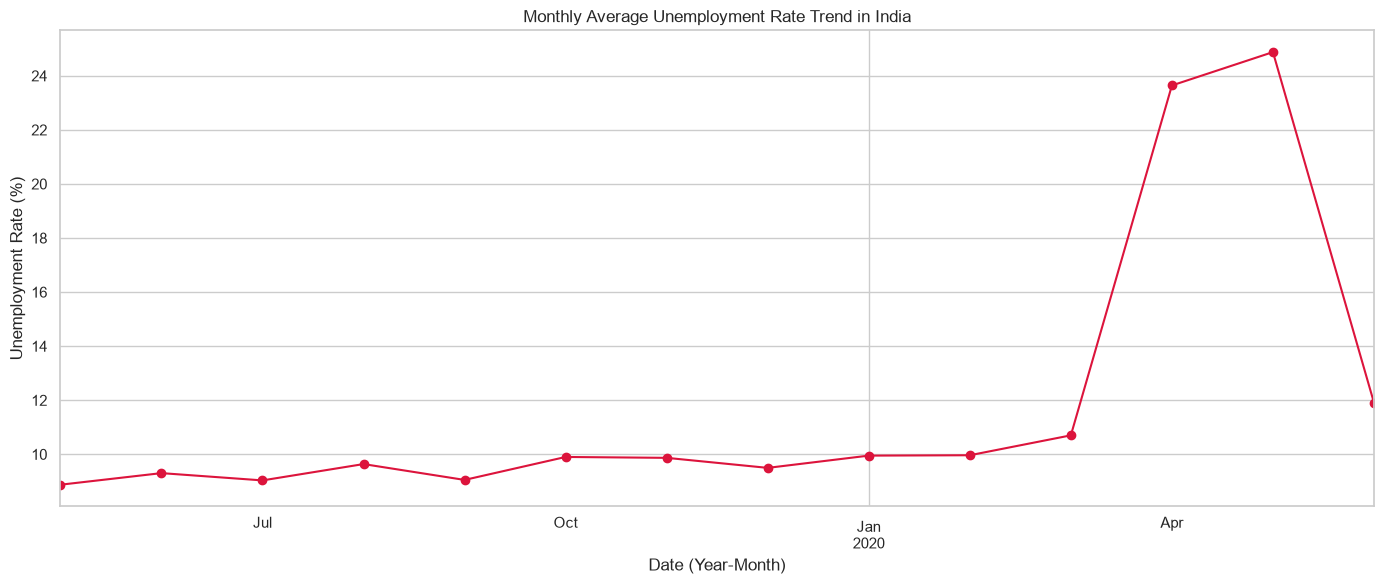

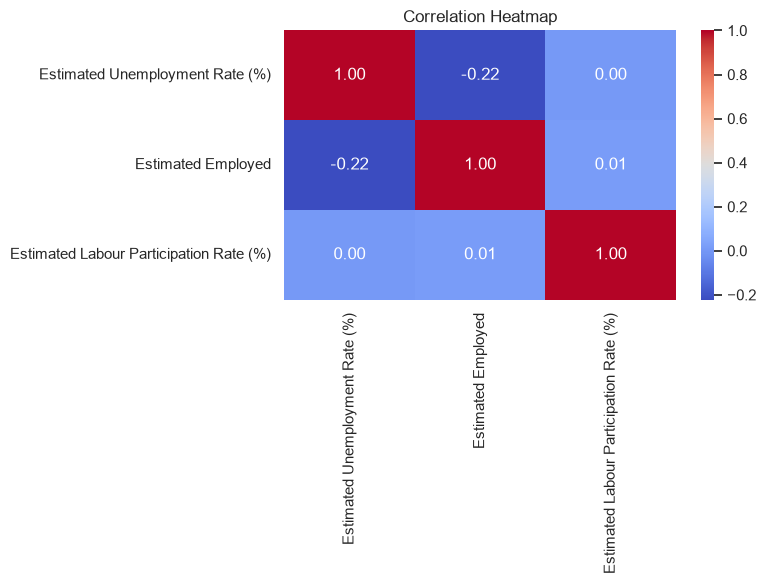


--- Pre vs Post COVID Analysis ---
Pre-COVID Average Unemployment Rate: 9.51%
Post-COVID Average Unemployment Rate: 17.77%


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setup Plot Style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# 1. DATA INGESTION & PIPELINE
df = pd.read_csv("Unemployment in India.csv")
df.columns = df.columns.str.strip()

print("--- Missing Values Check ---")
print(df.isnull().sum())

df.dropna(how='all', inplace=True)
df['Date'] = pd.to_datetime(df['Date'].str.strip(), format='%d-%m-%Y')
df['Region'] = df['Region'].str.strip()
df['Area'] = df['Area'].str.strip()

# 2. EXPLORATORY DATA ANALYSIS (EDA)
print("\n--- Summary Statistics ---")
print(df.describe())

region_avg = df.groupby('Region')['Estimated Unemployment Rate (%)'].mean().reset_index()
region_avg = region_avg.sort_values(by='Estimated Unemployment Rate (%)', ascending=False)

# Bar Chart
plt.figure(figsize=(12, 6))
sns.barplot(x='Estimated Unemployment Rate (%)', y='Region', data=region_avg.head(10), palette='viridis')
plt.title('Top 10 Regions/States by Highest Average Unemployment Rate')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('Region')
plt.tight_layout()
plt.savefig('top_10_unemployment_states.png')
plt.show()

# 3. TIME-SERIES & CORRELATION
df['Month'] = df['Date'].dt.to_period('M')
monthly_trend = df.groupby('Month')['Estimated Unemployment Rate (%)'].mean()

plt.figure(figsize=(14, 6))
monthly_trend.plot(kind='line', marker='o', color='crimson')
plt.title('Monthly Average Unemployment Rate Trend in India')
plt.xlabel('Date (Year-Month)')
plt.ylabel('Unemployment Rate (%)')
plt.grid(True)
plt.tight_layout()
plt.savefig('monthly_unemployment_trend.png')
plt.show()

plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()

# 4. PRE VS POST COVID COMPARISON
pre_covid = df[df['Date'] < '2020-03-01']
post_covid = df[df['Date'] >= '2020-03-01']

print("\n--- Pre vs Post COVID Analysis ---")
print(f"Pre-COVID Average Unemployment Rate: {pre_covid['Estimated Unemployment Rate (%)'].mean():.2f}%")
print(f"Post-COVID Average Unemployment Rate: {post_covid['Estimated Unemployment Rate (%)'].mean():.2f}%")
